In [1]:
import sys
sys.path.append("..")
from src.data import load_split

train2 = load_split("../data/raw/train_FD002.txt")
print(train2.shape)

conds = train2[["setting_1", "setting_2", "setting_3"]].round(
    {"setting_1": 0, "setting_2": 1, "setting_3": 0}
)
print(conds.value_counts().sort_index())

(53759, 26)
setting_1  setting_2  setting_3
0.0        0.0        100.0         8044
10.0       0.2        100.0         4138
           0.3        100.0         3958
20.0       0.7        100.0         8122
25.0       0.6        60.0          8002
35.0       0.8        100.0         8037
42.0       0.8        100.0        13458
Name: count, dtype: int64


In [2]:
train2["cond"] = (
    train2["setting_1"].round(0).astype(int).astype(str) + "_"
    + train2["setting_2"].round(2).astype(str) + "_"
    + train2["setting_3"].round(0).astype(int).astype(str)
)
print(train2["cond"].value_counts().sort_index())
print("Number of conditions:", train2["cond"].nunique())

cond
0_0.0_100       8044
10_0.25_100     8096
20_0.7_100      8122
25_0.62_60      8002
35_0.84_100     8037
42_0.84_100    13458
Name: count, dtype: int64
Number of conditions: 6


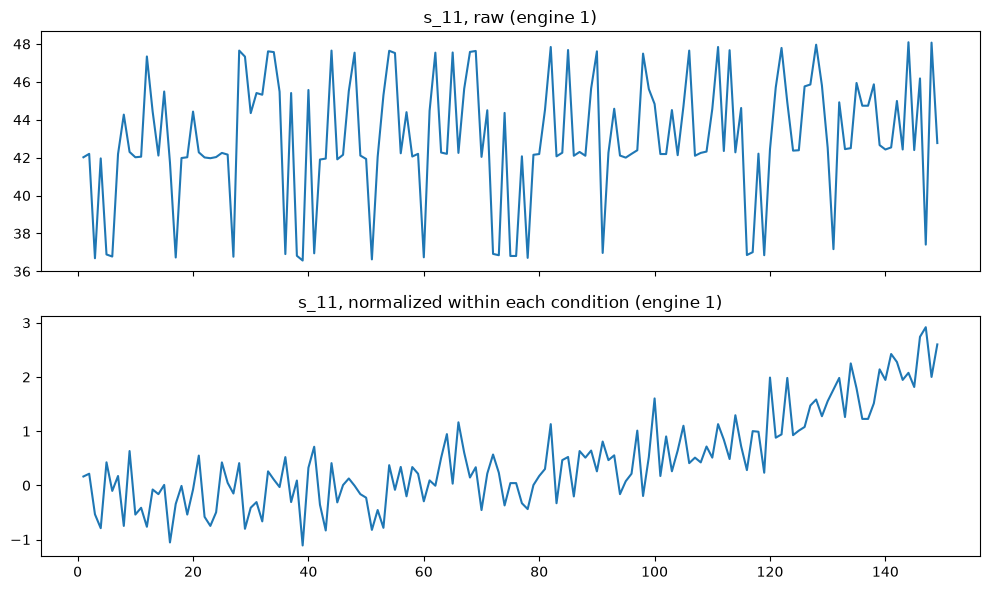

In [3]:
import numpy as np
import matplotlib.pyplot as plt

sensor_cols = [c for c in train2.columns if c.startswith("s_")]

g = train2.groupby("cond")[sensor_cols]
cond_mean = g.transform("mean")
cond_std = g.transform("std").replace(0, 1)
train2_norm = (train2[sensor_cols] - cond_mean) / cond_std

e = train2["unit"] == 1
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(train2.loc[e, "cycle"], train2.loc[e, "s_11"])
axes[0].set_title("s_11, raw (engine 1)")
axes[1].plot(train2.loc[e, "cycle"], train2_norm.loc[e, "s_11"])
axes[1].set_title("s_11, normalized within each condition (engine 1)")
plt.tight_layout()
plt.show()

In [4]:
test2 = load_split("../data/raw/test_FD002.txt")

def add_cond(df):
    df["cond"] = (
        df["setting_1"].round(0).astype(int).astype(str) + "_"
        + df["setting_2"].round(2).astype(str) + "_"
        + df["setting_3"].round(0).astype(int).astype(str)
    )
    return df

test2 = add_cond(test2)

keep = ["s_2", "s_3", "s_4", "s_7", "s_8", "s_9", "s_11",
        "s_12", "s_13", "s_14", "s_15", "s_17", "s_20", "s_21"]

cond_mean = train2.groupby("cond")[keep].mean()
cond_std = train2.groupby("cond")[keep].std()

def normalize(df):
    out = df.copy()
    m = cond_mean.loc[df["cond"]].to_numpy()
    s = cond_std.loc[df["cond"]].to_numpy()
    out[keep] = (df[keep].to_numpy() - m) / s
    return out

train2_n = normalize(train2)
test2_n = normalize(test2)

print("Conditions only in test:", set(test2["cond"]) - set(train2["cond"]))
print("Train normalized: mean", train2_n[keep].mean().abs().max().round(3),
      " std", train2_n[keep].std().round(2).min(), "to", train2_n[keep].std().round(2).max())
print("Test normalized:  min", test2_n[keep].min().min().round(1),
      " max", test2_n[keep].max().max().round(1))

Conditions only in test: set()
Train normalized: mean 0.0  std 1.0 to 1.0
Test normalized:  min -4.1  max 6.4


In [5]:
from src.data import load_rul

RUL_CAP = 125

# training labels
train2_n["rul"] = train2_n.groupby("unit")["cycle"].transform("max") - train2_n["cycle"]
train2_n["rul_capped"] = train2_n["rul"].clip(upper=RUL_CAP)

# 5-cycle rolling averages, computed per engine
def add_rolling(df, window=5):
    avg = df.groupby("unit")[keep].transform(lambda x: x.rolling(window, min_periods=1).mean())
    avg.columns = [f"{c}_avg{window}" for c in keep]
    return pd.concat([df, avg], axis=1)

import pandas as pd
train2_n = add_rolling(train2_n)
test2_n = add_rolling(test2_n)

true_rul2 = load_rul("../data/raw/RUL_FD002.txt")

print("Train engines:", train2_n["unit"].nunique(), " rows:", len(train2_n))
print("Test engines:", test2_n["unit"].nunique(), " true RUL rows:", len(true_rul2))
print("Train feature columns:", len([c for c in train2_n.columns if c.startswith("s_")]))

test_len = test2_n.groupby("unit")["cycle"].max()
print("Test history length: min", test_len.min(), " median", int(test_len.median()), " max", test_len.max())
print("Test engines shorter than 30 cycles:", int((test_len < 30).sum()))

Train engines: 260  rows: 53759
Test engines: 259  true RUL rows: 259
Train feature columns: 35
Test history length: min 21  median 132  max 367
Test engines shorter than 30 cycles: 6


In [6]:
import numpy as np

WINDOW = 30
feature_cols = keep + [f"{c}_avg5" for c in keep]
print("Features used:", len(feature_cols))

def make_train_windows(df, window=WINDOW):
    X, y, units = [], [], []
    for unit, g in df.groupby("unit"):
        g = g.sort_values("cycle")
        values = g[feature_cols].to_numpy(dtype="float32")
        labels = g["rul_capped"].to_numpy(dtype="float32")
        for end in range(window, len(g) + 1):
            X.append(values[end - window:end])
            y.append(labels[end - 1])
            units.append(unit)
    return np.array(X), np.array(y), np.array(units)

def make_test_windows(df, window=WINDOW):
    X, units = [], []
    for unit, g in df.groupby("unit"):
        g = g.sort_values("cycle")
        values = g[feature_cols].to_numpy(dtype="float32")
        if len(values) < window:
            pad = np.repeat(values[:1], window - len(values), axis=0)
            values = np.vstack([pad, values])
        X.append(values[-window:])
        units.append(unit)
    return np.array(X), np.array(units)

X_train2, y_train2, units_train2 = make_train_windows(train2_n)
X_test2, units_test2 = make_test_windows(test2_n)
y_test2 = true_rul2["rul"].to_numpy(dtype="float32")

print(X_train2.shape, y_train2.shape)
print(X_test2.shape, y_test2.shape)
print("Units line up:", (units_test2 == np.arange(1, len(y_test2) + 1)).all())
print("True RUL range:", y_test2.min(), "to", y_test2.max())

Features used: 28
(46219, 30, 28) (46219,)
(259, 30, 28) (259,)
Units line up: True
True RUL range: 6.0 to 194.0


In [7]:
rng = np.random.default_rng(42)
all_units = np.unique(units_train2)
val_units = rng.choice(all_units, size=52, replace=False)
val_mask = np.isin(units_train2, val_units)

X_tr2, y_tr2 = X_train2[~val_mask], y_train2[~val_mask]
X_val2, y_val2 = X_train2[val_mask], y_train2[val_mask]

print("Train:", X_tr2.shape, " Val:", X_val2.shape)
print("Total windows:", len(X_tr2) + len(X_val2))
print("Engines shared between train and val:",
      len(set(units_train2[~val_mask]) & set(units_train2[val_mask])))

np.savez("../data/processed/windows_fd002.npz",
         X_tr=X_tr2, y_tr=y_tr2, X_val=X_val2, y_val=y_val2,
         X_test=X_test2, y_test=y_test2)

Train: (37174, 30, 28)  Val: (9045, 30, 28)
Total windows: 46219
Engines shared between train and val: 0
